In [1]:
import argparse
from pyspark.sql import SparkSession, functions as F
import os, re
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
from pyspark.sql.functions import col, split, trim, size, when, length, element_at, regexp_replace
import pandas
import numpy
import math


In [4]:
spark = (
    SparkSession.builder
    .appName("rename-and-save-1")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
        .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
        # HDFS endpoint (from docker-compose: hdfs-namenode on port 9000)
        .config("spark.hadoop.fs.defaultFS", "hdfs://hdfs-namenode:9000")
        # small local-friendly shuffle
        .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

In [6]:
silver_parent_path = "hdfs:///data/delta/silver"  

In [74]:
silver_churn_demographics = silver_parent_path + '/churn_demographics'
silver_churn_location = silver_parent_path + '/churn_location'
silver_churn_population = silver_parent_path + '/churn_population'
silver_churn_services = silver_parent_path + '/churn_services'
silver_churn_status = silver_parent_path + '/churn_status'
	


df_churn_demographics = spark.read.format("delta").load(silver_churn_demographics)
df_churn_location = spark.read.format("delta").load(silver_churn_location)
df_churn_population = spark.read.format("delta").load(silver_churn_population)
df_churn_services = spark.read.format("delta").load(silver_churn_services)
df_churn_status = spark.read.format("delta").load(silver_churn_status)

In [75]:
df_churn_demographics.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- under_30: boolean (nullable = true)
 |-- senior_citizen: boolean (nullable = true)
 |-- married: boolean (nullable = true)
 |-- dependents: boolean (nullable = true)
 |-- num_dependents: integer (nullable = true)
 |-- ingest_date: date (nullable = true)
 |-- loaded_at: timestamp (nullable = true)



In [76]:
df_churn_location.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- count_val: integer (nullable = true)
 |-- city: string (nullable = true)
 |-- zip_code: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- ingest_date: date (nullable = true)
 |-- loaded_at: timestamp (nullable = true)



In [77]:
df_churn_population.printSchema()

root
 |-- id: integer (nullable = true)
 |-- zip_code: integer (nullable = true)
 |-- population: integer (nullable = true)
 |-- ingest_date: date (nullable = true)
 |-- loaded_at: timestamp (nullable = true)



In [78]:
df_churn_services.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- count_val: integer (nullable = true)
 |-- quarter: string (nullable = true)
 |-- referred_a_friend: boolean (nullable = true)
 |-- num_referrals: integer (nullable = true)
 |-- tenure_in_months: integer (nullable = true)
 |-- offer: string (nullable = true)
 |-- phone_service: boolean (nullable = true)
 |-- avg_monthly_long_distance_charges: double (nullable = true)
 |-- multiple_lines: boolean (nullable = true)
 |-- internet_service: boolean (nullable = true)
 |-- internet_type: string (nullable = true)
 |-- avg_monthly_gb_download: integer (nullable = true)
 |-- online_security: boolean (nullable = true)
 |-- online_backup: boolean (nullable = true)
 |-- device_protection_plan: boolean (nullable = true)
 |-- premium_tech_support: boolean (nullable = true)
 |-- streaming_tv: boolean (nullable = true)
 |-- streaming_movies: boolean (nullable = true)
 |-- streaming_music: boolean (nullable = true)
 |-- unlimited_data: boolean (nullabl

In [79]:
df_churn_status.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- quarter: string (nullable = true)
 |-- satisfaction_score: integer (nullable = true)
 |-- customer_status: string (nullable = true)
 |-- churn_label: string (nullable = true)
 |-- churn_value: integer (nullable = true)
 |-- churn_score: integer (nullable = true)
 |-- cltv: integer (nullable = true)
 |-- churn_category: string (nullable = true)
 |-- churn_reason: string (nullable = true)
 |-- churn_flag: boolean (nullable = true)
 |-- customer_status_std: string (nullable = true)
 |-- ingest_date: date (nullable = true)
 |-- customer_status_code: integer (nullable = true)



There's two column name `count_val` and `quarter` . lets find out if they have the same data or not

In [87]:
df_churn_status_quarter = df_churn_status.select('quarter').toPandas()['quarter']
df_churn_services_quarter = df_churn_services.select('quarter').toPandas()['quarter']

print(df_churn_status_quarter.equals(df_churn_services_quarter))

True


In [84]:
df_churn_services_count_val = df_churn_services.select('count_val').toPandas()['count_val']
df_churn_location_count_val = df_churn_location.select('count_val').toPandas()['count_val']

print(df_churn_services_count_val.equals(df_churn_location_count_val))

True

**So both of the column have same data. As such, we can just drop one of the column.**

In [94]:
df_churn_status = df_churn_status.drop('quarter')
df_churn_services = df_churn_services.drop('count_val')

In [99]:
df_churn_status.printSchema()

root
 |-- customer_id: string (nullable = true)
 |-- satisfaction_score: integer (nullable = true)
 |-- customer_status: string (nullable = true)
 |-- churn_label: string (nullable = true)
 |-- churn_value: integer (nullable = true)
 |-- churn_score: integer (nullable = true)
 |-- cltv: integer (nullable = true)
 |-- churn_category: string (nullable = true)
 |-- churn_reason: string (nullable = true)
 |-- churn_flag: boolean (nullable = true)
 |-- customer_status_std: string (nullable = true)
 |-- ingest_date: date (nullable = true)
 |-- customer_status_code: integer (nullable = true)



### No we need to remove the ingest_at and loaded_at from each columns

In [100]:
df_churn_demographics = df_churn_demographics.drop("ingest_date").drop("loaded_at")
df_churn_location = df_churn_location.drop("ingest_date").drop("loaded_at")
df_churn_population = df_churn_population.drop("ingest_date").drop("loaded_at")
df_churn_services = df_churn_services.drop("ingest_date").drop("loaded_at")
df_churn_status = df_churn_status.drop("ingest_date").drop("loaded_at")

In [105]:
all_columns = df_churn_demographics.columns + df_churn_location.columns + df_churn_population.columns + df_churn_services.columns + df_churn_status.columns 

In [114]:
from collections import Counter

# all_columns = df.columns
counts = Counter(all_columns)
duplicates = [col for col, count in counts.items() if count > 1]
duplicates

['customer_id', 'zip_code']

### So now we've `customer_id` and `zip_code` duplicate. it's necessary for joning

In [115]:
df_churn_location_joined_population = df_churn_location.join(df_churn_population, on ='zip_code', how = 'left')

# Joining demographics, location and population

In [116]:
df_churn_demographics_joined_location_and_population = df_churn_demographics.join(df_churn_location_joined_population, on='customer_id', how = 'left')

In [ ]:
df_churn_demographics_joined_location_and_population.printSchema()

In [118]:
fully_joined_df = df_churn_demographics_joined_location_and_population.join(df_churn_services, on='customer_id', how='left').join(df_churn_status,on='customer_id', how='left')

In [ ]:
fully_joined_df.printSchema()

Fully joined. now lets find out if there's duplicate column or not

In [120]:
counts = Counter(fully_joined_df.columns)
duplicates = [col for col, count in counts.items() if count > 1]
duplicates

[]

# Now do analysis on the Data.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assume df is now pandas
fully_joined_df_pandas = fully_joined_df.toPandas()

# Basic info
print("Shape:", fully_joined_df_pandas.shape)
fully_joined_df_pandas.info()

### Removing columns where column has one distinct value

In [132]:
neweric_columns = fully_joined_df_pandas.select_dtypes(include=["number"]).columns.tolist()

In [145]:
cols = fully_joined_df_pandas.columns

distinct_count_dict = fully_joined_df.select(
    *[F.countDistinct(c).alias(f"{c}_distinct") for c in cols]
).first().asDict()


In [150]:
only_one_distinct_value_columns = {val: cols for val, cols in distinct_count_dict.items() if cols == 1}
only_one_distinct_value_columns

{'count_val_distinct': 1, 'quarter_distinct': 1}

### Since count_val and quarter only have one same value let's drop those

In [151]:
fully_joined_df = fully_joined_df.drop('count_val').drop('quarter')

In [ ]:
import seaborn as sns

for col in neweric_columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(fully_joined_df_pandas[col].dropna(),kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

In [ ]:
fully_joined_df.printSchema()

## Now we save the dataframe

In [155]:
gold_location_path = "hdfs:///data/delta/gold/fully_joined"

fully_joined_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(gold_location_path)

# Now let's convert all boolean and string to int

# [Checkpoint] This is where we can load the df from memory. 

In [542]:
gold_location_path = "hdfs:///data/delta/gold/fully_joined"

fully_joined_df = spark.read.format("delta").load(gold_location_path)

In [543]:
from pyspark.sql import functions as F, types as T
import re

def sanitize(s: str) -> str:
    """Make category values safe for column names."""
    if s is None:
        return "_NULL_"
    s = str(s)
    s = s.strip()
    s = re.sub(r"\s+", "_", s)          # spaces -> underscore
    s = re.sub(r"[^0-9a-zA-Z_]", "_", s) # non-alnum -> underscore
    if not s:
        s = "_EMPTY_"
    return s

def manual_one_hot_all_string_column(df, ignore_columns = []):
    columns = [f.name for f in df.schema.fields if isinstance(f.dataType, T.StringType)]
    print("processing columns", columns)
    result_df = df
    categories_map = {}

    for column in columns:
        if column in ignore_columns:
            continue
        print("started column: ", column)
        # figure out categories (capped)
        categoriess_df = (result_df
                   .select(column)
                   .groupBy(column)
                   .agg(F.count("*").alias("count"))
                   .orderBy(F.desc("count")))

        cats = [row[column] for row in categoriess_df.collect()]  # small list to driver
        
        category_value_column_map = {}
        # add indicator columns
        for category_item in cats:
            colname = f"{column}__{sanitize(category_item)}"
            category_value_column_map[category_item] = colname
            result_df = result_df.withColumn(
                colname,
                F.when(F.col(column).eqNullSafe(F.lit(category_item)), F.lit(1)).otherwise(F.lit(0))
            )
        categories_map[column] = category_value_column_map
        print("finished column: ", column)
    return result_df, categories_map


In [544]:
df,categories_string_column_encoding_map = manual_one_hot_all_string_column(fully_joined_df, ['customer_id','city','customer_status', 'churn_label', 'churn_category', 'churn_reason'])

processing columns ['customer_id', 'gender', 'city', 'offer', 'internet_type', 'contract', 'payment_method', 'customer_status', 'churn_label', 'churn_category', 'churn_reason', 'customer_status_std']
started column:  gender
finished column:  gender
started column:  offer
finished column:  offer
started column:  internet_type
finished column:  internet_type
started column:  contract
finished column:  contract
started column:  payment_method
finished column:  payment_method
started column:  customer_status_std
finished column:  customer_status_std


In [ ]:
df.printSchema()

In [546]:
def convert_booleans_to_ints(df):
    bool_cols = [f.name for f in df.schema.fields if isinstance(f.dataType, T.BooleanType)]

    result_df = df
    modified_new_column_map = {}
    for c in bool_cols:
        new_col = f"{c}_as_int"
        result_df = result_df.withColumn(
            new_col,
            F.when(F.col(c) == True, F.lit(1))
             .when(F.col(c) == False, F.lit(0))
        )
        modified_new_column_map[c] = new_col

    return result_df , modified_new_column_map

In [547]:
df,convert_booleans_to_ints = convert_booleans_to_ints(df)

In [548]:
int_columns = [f.name for f in df.schema.fields if isinstance(f.dataType, T.IntegerType)]

In [549]:
string_encoded_columns = [y for x in categories_string_column_encoding_map.values() for y in x.values()]

In [550]:
booleans_to_int_columns = convert_booleans_to_ints.values()

In [551]:
all_feature_columns = list(int_columns) + list(string_encoded_columns) + list(booleans_to_int_columns)

In [554]:
remove_feature = ['id','offer_code','internet_type_code','churn_value','churn_score','cltv','customer_status_code','churn_flag_as_int', 'customer_status_std__stayed','customer_status_std__joined','zip_code',]
all_feature_and_label = [x for x in all_feature_columns if x not in remove_feature]

In [555]:
all_feature_and_label

['age',
 'num_dependents',
 'population',
 'num_referrals',
 'tenure_in_months',
 'avg_monthly_gb_download',
 'total_extra_data_charges',
 'satisfaction_score',
 'gender__Male',
 'gender__Female',
 'offer__None',
 'offer__Offer_B',
 'offer__Offer_E',
 'offer__Offer_D',
 'offer__Offer_A',
 'offer__Offer_C',
 'internet_type__Fiber_Optic',
 'internet_type__DSL',
 'internet_type__None',
 'internet_type__Cable',
 'contract__Month_to_Month',
 'contract__Two_Year',
 'contract__One_Year',
 'payment_method__Bank_Withdrawal',
 'payment_method__Credit_Card',
 'payment_method__Mailed_Check',
 'customer_status_std__churned',
 'under_30_as_int',
 'senior_citizen_as_int',
 'married_as_int',
 'dependents_as_int',
 'referred_a_friend_as_int',
 'phone_service_as_int',
 'multiple_lines_as_int',
 'internet_service_as_int',
 'online_security_as_int',
 'online_backup_as_int',
 'device_protection_plan_as_int',
 'premium_tech_support_as_int',
 'streaming_tv_as_int',
 'streaming_movies_as_int',
 'streaming_mus

In [558]:
label_column = 'customer_status_std__churned'

all_feature_columns = [ x for x in all_feature_and_label if x != label_column]

## Divite in train validation set

In [560]:
df_train, df_val = df.randomSplit([0.70, 0.3], seed=42)

In [561]:
vector_assembler = VectorAssembler(
    inputCols=all_feature_columns, outputCol="raw_features", handleInvalid="keep"
)

In [562]:
transformed_df_train = vector_assembler.transform(df_train)
transformed_df_val = vector_assembler.transform(df_val)

In [563]:
scaler = StandardScaler(
        inputCol="raw_features", outputCol="features", withMean=True, withStd=True
    )

In [564]:
scaler_fitted = scaler.fit(transformed_df_train)

In [565]:
transformed_df_train = scaler_fitted.transform(transformed_df_train)
transformed_df_val = scaler_fitted.transform(transformed_df_val)

In [566]:
lr = LogisticRegression(
        featuresCol="features",
        labelCol=label_column,
        predictionCol="prediction",
        probabilityCol="probability",
        rawPredictionCol="rawPrediction"
    )

In [567]:
blorModel = lr.fit(transformed_df_train)

In [568]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

In [569]:
roc_evaluator = BinaryClassificationEvaluator(
        labelCol="churn_flag_as_int", rawPredictionCol="rawPrediction", metricName="areaUnderROC",
)
evaluator_acc = MulticlassClassificationEvaluator(
        labelCol="churn_flag_as_int", predictionCol="prediction", metricName="accuracy")
evaluator_f1 = MulticlassClassificationEvaluator(
        labelCol="churn_flag_as_int", predictionCol="prediction", metricName="f1")

In [570]:
df_val_predicted = blorModel.transform(transformed_df_val)

In [571]:
auc_roc = roc_evaluator.evaluate(df_val_predicted)
acc = evaluator_acc.evaluate(df_val_predicted)
f1 = evaluator_f1.evaluate(df_val_predicted)

In [572]:
auc_roc

0.9910680752673068

In [573]:
acc

0.9601395117090185

In [574]:
f1

0.959651590207738

In [536]:
np.argmax(np.abs(blorModel.coefficients))

3

In [537]:
blorModel.coefficients[6]

0.00042029445332267235

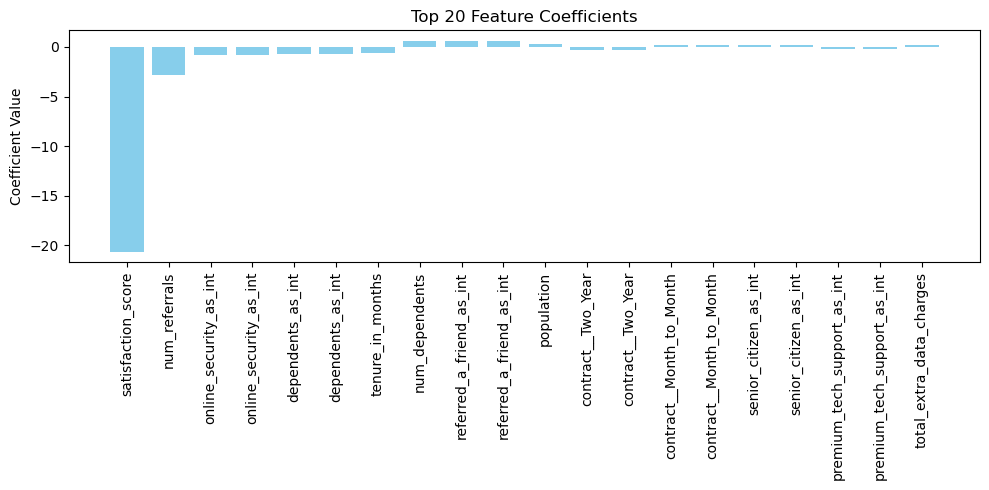

In [581]:
import matplotlib.pyplot as plt
import numpy as np

# Get features and coefficients
feature_names = vector_assembler.getInputCols()
coefficients = blorModel.coefficients.toArray()

# Sort by absolute coefficient magnitude (largest first)
sorted_idx = np.argsort(np.abs(coefficients))[::-1]
sorted_features = np.array(feature_names)[sorted_idx]
sorted_coeffs = coefficients[sorted_idx]

# Set how many top features to plot (None = all)
top_n = 20   # change to None to show all

if top_n is not None:
    sorted_features = sorted_features[:top_n]
    sorted_coeffs = sorted_coeffs[:top_n]

# --- Bar chart ---
plt.figure(figsize=(max(8, (top_n or len(sorted_features)) / 2), 5))
plt.bar(range(len(sorted_coeffs)), sorted_coeffs, color='skyblue')
plt.xticks(range(len(sorted_features)), sorted_features, rotation=90)
plt.title(f"Top {top_n or len(sorted_features)} Feature Coefficients")
plt.ylabel("Coefficient Value")
plt.tight_layout()
plt.show()


In [586]:
import seaborn as sns

df_as_pandas = df.toPandas()

In [588]:
df_as_pandas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 93 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   customer_id                        7043 non-null   object 
 1   gender                             7043 non-null   object 
 2   age                                7043 non-null   int32  
 3   under_30                           7043 non-null   bool   
 4   senior_citizen                     7043 non-null   bool   
 5   married                            7043 non-null   bool   
 6   dependents                         7043 non-null   bool   
 7   num_dependents                     7043 non-null   int32  
 8   zip_code                           7043 non-null   int32  
 9   city                               7043 non-null   object 
 10  latitude                           7043 non-null   float64
 11  longitude                          7043 non-null   float

In [594]:
a = df_as_pandas[all_feature_columns + [label_column]]

<Axes: >

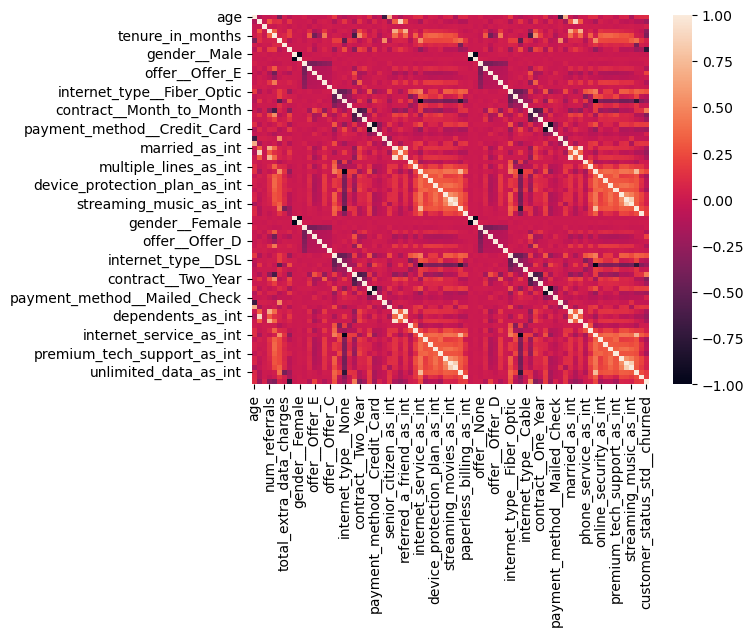

In [599]:
corr = a.corr()

sns.heatmap(corr)
